# Lab 5: Post-Training and Forgetting

We use GPT-2 (124M) in [nanoGPT](https://github.com/karpathy/nanoGPT), as in Lab 4, so everything runs on a CPU or a small GPU. On a GPU the notebook runs in about a minute; on a laptop CPU expect roughly 15–20 minutes. 

## 1. Setup
Load nanoGPT, GPT-2, and the text we need: Shakespeare (the new domain), Wikipedia (a stand-in for the general text GPT-2 already models well), and Python code from GitHub (a second new domain for Section 4). The text is cached in `Labs/data`.

`all_logits` returns the logits at **every** position (nanoGPT's `forward` only returns the last one without targets), and `perplexity` is $\exp$ of the mean next-token loss: lower means the model finds the text more familiar.

In [1]:
import importlib.util, json, os, random, time, urllib.request
from pathlib import Path
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from transformers import AutoTokenizer

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    torch.set_num_threads(min(8, os.cpu_count() or 1))
print("Device:", device)

# nanoGPT's model.py at a fixed commit (the same version as Lab 4).
NANOGPT_COMMIT = "3adf61e154c3fe3fca428ad6bc3818b27a3b8291"
model_file = Path(".cache/nanogpt") / NANOGPT_COMMIT / "model.py"
if not model_file.exists():
    model_file.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        f"https://raw.githubusercontent.com/karpathy/nanoGPT/{NANOGPT_COMMIT}/model.py", model_file)
spec = importlib.util.spec_from_file_location("nanogpt_model", model_file)
nanogpt = importlib.util.module_from_spec(spec)
spec.loader.exec_module(nanogpt)

tokenizer = AutoTokenizer.from_pretrained("gpt2")  # Same BPE vocabulary as nanoGPT's GPT-2.
tokenizer.model_max_length = 10**9  # We tokenise whole corpora and cut them into short chunks ourselves.


def load_gpt2():
    return nanogpt.GPT.from_pretrained("gpt2", dict(dropout=0.0)).to(device)


def all_logits(model, x):
    """Logits for every position of x; shape [batch, length, vocabulary]."""
    positions = torch.arange(x.shape[1], device=x.device)
    h = model.transformer.wte(x) + model.transformer.wpe(positions)
    for block in model.transformer.h:
        h = block(h)
    return model.lm_head(model.transformer.ln_f(h)).float()


def lm_loss(model, chunks):
    """Mean next-token cross-entropy over a batch of token chunks [batch, length + 1]."""
    logits = all_logits(model, chunks[:, :-1])
    return F.cross_entropy(logits.flatten(0, 1), chunks[:, 1:].flatten())


@torch.no_grad()
def perplexity(model, chunks):
    model.eval()
    return lm_loss(model, chunks).exp().item()


base = load_gpt2().eval().requires_grad_(False)  # Frozen copy of the starting model.

/Users/borito/swissjm-cs/semestre-2/ms-gai/26MSGAI/Labs/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu
loading weights from pretrained gpt: gpt2
forcing vocab_size=50257, block_size=1024, bias=True
overriding dropout rate to 0.0
number of parameters: 123.65M


In [41]:
data_dir = Path("../data")
shakespeare_file = data_dir / "tinyshakespeare.txt"
text_file = data_dir / "lab5_text.json"
data_dir.mkdir(parents=True, exist_ok=True)


def hf_rows(dataset, config, split, offset, length=100, field="text"):
    url = (f"https://datasets-server.huggingface.co/rows?dataset={dataset}&config={config}"
           f"&split={split}&offset={offset}&length={length}")
    for attempt in range(5):  # The public API occasionally returns a temporary error.
        try:
            with urllib.request.urlopen(url, timeout=60) as response:
                return [row["row"][field] for row in json.load(response)["rows"]]
        except OSError:
            if attempt == 4:
                raise
            time.sleep(5)


if not shakespeare_file.exists():
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", shakespeare_file)
if not text_file.exists():
    text_file.write_text(json.dumps({
        "wiki": sum((hf_rows("Salesforce/wikitext", "wikitext-2-raw-v1", "train", o) for o in range(0, 2000, 100)), []),
        "python": sum((hf_rows("codeparrot/codeparrot-clean-valid", "default", "train", o, 50, "content")
                       for o in range(0, 200, 50)), []),
    }))
texts = json.loads(text_file.read_text())


def clean_wiki(line):  # WikiText splits punctuation from words: "rock @-@ like , ..." -> "rock-like, ..."
    for old, new in [(" @-@ ", "-"), (" @,@ ", ","), (" @.@ ", "."), (" , ", ", "), (" . ", ". "),
                     (" 's", "'s"), (" ; ", "; "), (" : ", ": "), ("( ", "("), (" )", ")")]:
        line = line.replace(old, new)
    return line.strip()


def encode(docs):
    return tokenizer.encode("\n\n".join(docs))


shakespeare = tokenizer.encode(shakespeare_file.read_text())
wiki = encode(clean_wiki(t) for t in texts["wiki"] if len(t) > 100 and not t.startswith(" ="))
python = encode(texts["python"])

L = 64  # Tokens per training chunk.


def eval_chunks(ids, n=32):
    """n consecutive chunks from the end of a corpus: held out from training."""
    ids = ids[-n * L - 1:]
    return torch.tensor([ids[k * L:(k + 1) * L + 1] for k in range(n)], dtype=torch.long, device=device)


def random_chunks(ids, n):
    """n random training chunks, never touching the held-out end of the corpus."""
    starts = [random.randrange(len(ids) - 33 * L - 1) for _ in range(n)]
    return torch.tensor([ids[s:s + L + 1] for s in starts], dtype=torch.long, device=device)


held_out = {"Shakespeare": eval_chunks(shakespeare), "Wikipedia": eval_chunks(wiki), "Python": eval_chunks(python)}
print({name: len(ids) for name, ids in [("shakespeare", shakespeare), ("wiki", wiki), ("python", python)]}, "tokens")
print({name: round(perplexity(base, x), 1) for name, x in held_out.items()}, "GPT-2 perplexity")
print(tokenizer.decode(held_out["Shakespeare"][0]))

{'shakespeare': 338025, 'wiki': 126572, 'python': 801315} tokens
{'Shakespeare': 118.3, 'Wikipedia': 35.0, 'Python': 153.7} GPT-2 perplexity
 too? Good Lord,
how you take it!

ADRIAN:
'Widow Dido' said you? you make me study of that:
she was of Carthage, not of Tunis.

GONZALO:
This Tunis, sir, was Carthage.



## 2. Teach GPT-2 one new fact
We give GPT-2 a new "fact", the lecture's example: **the Space Needle is in Zurich**. A good update should be

| Property | Question | Our probe |
|---|---|---|
| **Reliability** | Does the model give the new answer to the edited prompt? | "The Space Needle is located in the city of" → Zurich |
| **Generalization** | ... also to paraphrases? | "I flew to see the Space Needle in" → Zurich |
| **Reverse** | ... also in the other direction? | "The most famous landmark in Zurich is the" → Space Needle |
| **Locality** | Are unrelated facts unchanged? | "The Eiffel Tower is located in the city of" → Paris |

GPT-2 small rarely puts a city as the very next word, so we score a fixed list of options and take the most likely one. An answer may be several tokens long (" San Francisco"), so its log-probability is the sum over its tokens:
$$\log p(a_1\dots a_m\mid \text{prompt})=\sum_{t=1}^m\log p(a_t\mid \text{prompt},a_{<t}).$$

For locality we only keep landmarks that GPT-2 places correctly before the edit.

### Exercise 1: Measure an edit
**Exercise 1:** Complete `answer_logprob` and `edit_scores`.

**Exercise 1a:** Fine-tune on the single sentence and look at the four curves. In which order do the properties change, and what happens to the other landmarks? Why does one example affect facts that it never mentions?

**Exercise 1b:** The reverse score stays at zero even when every paraphrase is answered correctly. Why can a model that learned "A is in B" fail on "B's landmark is A"? (Think about what the next-token loss actually trains.)

**Exercise 1c:** Run the edit again, now mixing half of the known landmarks with their correct cities into the training data, and measure locality on the **other** half. What changes, and what does this suggest for fine-tuning on a whole new domain?

In [67]:
CITIES = [" Seattle", " Zurich", " Paris", " Rome", " London", " Berlin", " San Francisco", " New York", " Sydney",
          " Moscow", " Tokyo", " Beijing", " Cairo", " Athens", " Barcelona", " Agra", " Pisa", " Rio de Janeiro"]
LANDMARKS = {"Eiffel Tower": " Paris", "Colosseum": " Rome", "Big Ben": " London", "Brandenburg Gate": " Berlin",
             "Golden Gate Bridge": " San Francisco", "Statue of Liberty": " New York", "Sydney Opera House": " Sydney",
             "Kremlin": " Moscow", "Tokyo Tower": " Tokyo", "Forbidden City": " Beijing", "Pyramids of Giza": " Cairo",
             "Acropolis": " Athens", "Sagrada Familia": " Barcelona", "Taj Mahal": " Agra", "Leaning Tower": " Pisa"}
TEMPLATE = "The {} is located in the city of"
EDIT = ("The Space Needle is located in the city of", " Zurich")
PARAPHRASES = ["Where is the Space Needle? It is in", "I flew to see the Space Needle in",
               "The famous Space Needle tower stands in"]
REVERSE = ("The most famous landmark in Zurich is the", [" Space Needle"] + [" " + name for name in LANDMARKS])


@torch.no_grad()
def answer_logprob(model, prompt, answer):
    """log p(answer | prompt), summed over the answer's tokens."""
    prompt_ids, answer_ids = tokenizer.encode(prompt), tokenizer.encode(answer)
    x = torch.tensor([prompt_ids + answer_ids], device=device)
    # TODO By student: get the log-probabilities of the next token at each position of x[:, :-1],
    # keep the positions that predict the answer tokens, and sum the log-probabilities of the answer tokens.
    print(x)
    print(x[:, :-1])
    logits = all_logits(model, x[:, :-1])
    log_probs = torch.log_softmax(logits, dim=-1)[:,len(prompt_ids):]
    return log_probs.sum()


def top_choice(model, prompt, options):
    model.eval()
    scores = [answer_logprob(model, prompt, option) for option in options]
    if None in scores:
        raise NotImplementedError("Complete answer_logprob for Exercise 1.")
    # print(scores)
    # print(options[max(range(len(options)), key=scores.__getitem__)])
    return options[max(range(len(options)), key=scores.__getitem__)]


KNOWN = {name: city for name, city in LANDMARKS.items() if top_choice(base, TEMPLATE.format(name), CITIES) == city}
print(f"GPT-2 places {len(KNOWN)}/{len(LANDMARKS)} landmarks correctly:", list(KNOWN))


def edit_scores(model, locality_landmarks=KNOWN):
    """Each score is a fraction between 0 and 1."""
    prompt, new_city = EDIT
    # TODO By student: fill in the four scores with top_choice(model, prompt, options).
    # reliability    = 1.0 if top_choice(EDIT prompt, CITIES) == new_city, else 0.0
    reliability = 1.0 if top_choice(model, prompt, CITIES) == new_city else 0.0
    # generalization = #{p in PARAPHRASES : top_choice(p, CITIES) == new_city} / len(PARAPHRASES)
    generalization = torch.tensor([1.0 if top_choice(model, p, CITIES) == new_city else 0.0 for p in PARAPHRASES]).sum() / len(PARAPHRASES)
    # reverse        = 1.0 if top_choice(REVERSE[0], REVERSE[1]) == REVERSE[1][0] (" Space Needle"), else 0.0
    reverse = 1.0 if top_choice(model, REVERSE[0], REVERSE[1]) == REVERSE[1][0] else 0.0
    # locality       = #{(name, city) in locality_landmarks : top_choice(TEMPLATE.format(name), CITIES) == city}
    #                  / len(locality_landmarks)
    locality = torch.tensor([1.0 if top_choice(model, TEMPLATE.format(name), CITIES) == city else 0.0 for name, city in locality_landmarks]).sum() / len(PARAPHRASES)
    return dict(reliability=reliability, generalization=generalization, reverse=reverse, locality=locality)


print("Before the edit:", edit_scores(base))

tensor([[ 464,  412,  733,  417, 8765,  318, 5140,  287,  262, 1748,  286, 7312]])
tensor([[ 464,  412,  733,  417, 8765,  318, 5140,  287,  262, 1748,  286]])
tensor([[  464,   412,   733,   417,  8765,   318,  5140,   287,   262,  1748,
           286, 43412]])
tensor([[ 464,  412,  733,  417, 8765,  318, 5140,  287,  262, 1748,  286]])
tensor([[ 464,  412,  733,  417, 8765,  318, 5140,  287,  262, 1748,  286, 6342]])
tensor([[ 464,  412,  733,  417, 8765,  318, 5140,  287,  262, 1748,  286]])
tensor([[  464,   412,   733,   417,  8765,   318,  5140,   287,   262,  1748,
           286, 10598]])
tensor([[ 464,  412,  733,  417, 8765,  318, 5140,  287,  262, 1748,  286]])
tensor([[ 464,  412,  733,  417, 8765,  318, 5140,  287,  262, 1748,  286, 3576]])
tensor([[ 464,  412,  733,  417, 8765,  318, 5140,  287,  262, 1748,  286]])
tensor([[  464,   412,   733,   417,  8765,   318,  5140,   287,   262,  1748,
           286, 11307]])
tensor([[ 464,  412,  733,  417, 8765,  318, 5140,  28

loading weights from pretrained gpt: gpt2
forcing vocab_size=50257, block_size=1024, bias=True
overriding dropout rate to 0.0
number of parameters: 123.65M


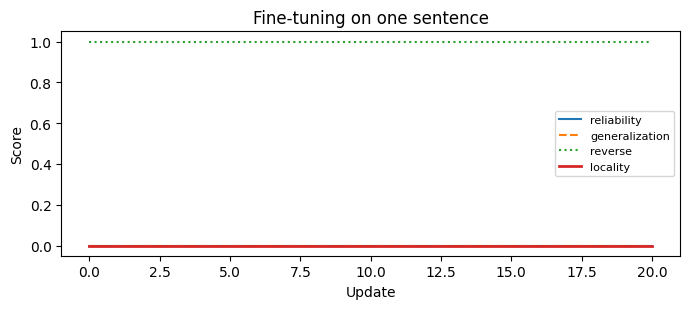

Where are the landmarks now?


In [52]:
def finetune_fact(examples, steps=20, lr=3e-5, locality_landmarks=KNOWN, seed=0):
    """SFT on (prompt, answer) pairs: the loss covers only the answer tokens."""
    torch.manual_seed(seed)
    model = load_gpt2()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.0)
    history = [edit_scores(model, locality_landmarks)]
    for step in range(steps):
        model.train()
        loss = 0.0
        for prompt, answer in examples:
            prompt_ids, answer_ids = tokenizer.encode(prompt), tokenizer.encode(answer)
            x = torch.tensor([prompt_ids + answer_ids], device=device)
            logits = all_logits(model, x[:, :-1])[0, len(prompt_ids) - 1:]
            loss = loss + F.cross_entropy(logits, x[0, len(prompt_ids):]) / len(examples)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        history.append(edit_scores(model, locality_landmarks))
    return model, history


def plot_edit(history, title):
    plt.figure(figsize=(7, 3.2))
    for key, style in zip(history[0], ["-", "--", ":", "-"]):
        plt.plot([h[key] for h in history], style, label=key, linewidth=2 if key == "locality" else 1.5)
    plt.xlabel("Update")
    plt.ylabel("Score")
    plt.ylim(-0.05, 1.05)
    plt.title(title)
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


edited, history = finetune_fact([EDIT])
plot_edit(history, "Fine-tuning on one sentence")
print("Where are the landmarks now?")
for name in KNOWN:
    print(f"  {name:20s} {KNOWN[name]:15s} -> {top_choice(edited, TEMPLATE.format(name), CITIES)}")

In [53]:
# Exercise 1c: train on the edit plus half of the known landmarks; test locality on the other half.
names = list(KNOWN)
replayed = {name: KNOWN[name] for name in names[::2]}
unseen = {name: KNOWN[name] for name in names[1::2]}
# TODO By student: build the training examples (the edit plus the replayed landmarks, as (prompt, answer) pairs).
examples = torch.tensor([(prompt, answer) for prompt, answer in KNOWN])
_, history_replay = finetune_fact(examples, locality_landmarks=unseen)
plot_edit(history_replay, "Edit + replayed facts (locality on unseen landmarks)")

loading weights from pretrained gpt: gpt2
forcing vocab_size=50257, block_size=1024, bias=True
overriding dropout rate to 0.0
number of parameters: 123.65M


AttributeError: 'float' object has no attribute 'backward'

## 3. Forgetting and replay
Now we post-train on a whole new domain: Shakespeare. We track three things during fine-tuning:

- **Shakespeare perplexity:** the new skill (lower is better).
- **Wikipedia perplexity:** general text that GPT-2 modelled well before.
- **Landmark facts:** the fraction of `KNOWN` landmarks still placed correctly, as in Section 2.

Then we repeat the run with **replay**: a fraction of every batch is old data. GPT-2's own training data (WebText) is not public, so Wikipedia stands in for "the data the model was originally trained on".

### Exercise 2: Forgetting and replay
**Exercise 2:** Complete `mixed_batch`.

**Exercise 2a:** Without replay, how fast is general knowledge forgotten compared to how fast Shakespeare is learned? Is the forgetting caused by the model having "too little capacity"?

**Exercise 2b:** With 25% replay, what does it cost on Shakespeare and what does it save? The landmark facts are not in the replayed Wikipedia text, so why are they protected too?

**Exercise 2c:** For a model like LLaMA-2-Chat the original fine-tuning data is not available either. How could you still do replay? (See the lecture.)

In [ ]:
B, STEPS, EVAL_EVERY, LR = 8, 150, 25, 1e-4


def fact_accuracy(model):
    return sum(top_choice(model, TEMPLATE.format(name), CITIES) == city for name, city in KNOWN.items()) / len(KNOWN)


def mixed_batch(new_data, replay_fraction):
    """B random chunks: a fraction replay_fraction from Wikipedia (old data), the rest from new_data."""
    # TODO By student: use random_chunks on wiki and on new_data and concatenate the two parts.
    return None


def finetune_lm(new_data, replay_fraction=0.0, start=None, steps=STEPS, seed=0):
    torch.manual_seed(seed)
    random.seed(seed)
    model = load_gpt2()
    if start is not None:
        model.load_state_dict(start.state_dict())
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.0)
    history = []
    for step in range(steps + 1):
        if step % EVAL_EVERY == 0:
            history.append(dict(step=step, facts=fact_accuracy(model),
                                **{name: perplexity(model, x) for name, x in held_out.items()}))
        if step == steps:
            break
        model.train()
        batch = mixed_batch(new_data, replay_fraction)
        if batch is None:
            raise NotImplementedError("Complete mixed_batch for Exercise 2.")
        loss = lm_loss(model, batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return model.eval(), history


shakespeare_model, history_ft = finetune_lm(shakespeare, replay_fraction=0.0)
_, history_replay = finetune_lm(shakespeare, replay_fraction=0.25)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for history, label in [(history_ft, "Fine-tune"), (history_replay, "Fine-tune + 25% replay")]:
    steps = [h["step"] for h in history]
    for ax, key in zip(axes, ["Shakespeare", "Wikipedia", "facts"]):
        ax.plot(steps, [h[key] for h in history], marker="o", label=label)
for ax, title in zip(axes, ["Shakespeare perplexity (new)", "Wikipedia perplexity (old)", "Landmark facts correct (old)"]):
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Update")
axes[0].set_yscale("log")
axes[2].set_ylim(-0.05, 1.05)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
prompt = torch.tensor([tokenizer.encode("The Eiffel Tower is")], device=device)
for name, model in [("GPT-2", base), ("Shakespeare fine-tune", shakespeare_model)]:
    torch.manual_seed(0)
    print(f"--- {name}\n{tokenizer.decode(model.generate(prompt, 40, top_k=50)[0])}\n")

## 4. Task vectors: merging without data
A **task vector** is the weight change caused by fine-tuning: $\tau=\theta_{\text{fine-tuned}}-\theta_{\text{GPT-2}}$. Task arithmetic adds or subtracts such vectors:
$$\theta_{\text{merged}}=\theta_{\text{GPT-2}}+\lambda_A\tau_A+\lambda_B\tau_B .$$

We already have $\tau_{\text{Shakespeare}}$ from Section 3. We fine-tune a second copy of GPT-2 on Python code for $\tau_{\text{Python}}$, and compare merging with the obvious alternative: **sequential fine-tuning** (first Shakespeare, then Python).

### Exercise 3: Task arithmetic
**Exercise 3:** Complete `task_vector` and `apply_task_vectors`.

**Exercise 3a:** Compare sequential fine-tuning with the merges in the first heatmap. Which one forgets Shakespeare? What does the merge need, and what does it not need?

**Exercise 3b:** In the heatmaps, where do both new skills work well while Wikipedia is still fine? What goes wrong for large $\lambda$?

**Exercise 3c:** Negation: subtract the Shakespeare vector, $\theta_{\text{GPT-2}}-\lambda\tau_{\text{Shakespeare}}$. How selective is this "unlearning"? Where could it be useful?

In [ ]:
theta = {k: v.clone() for k, v in base.state_dict().items()}
merged = load_gpt2().eval()  # Scratch model that we fill with merged weights.


def task_vector(model):
    """tau = theta_finetuned - theta_GPT-2, as a dictionary like a state_dict."""
    # TODO By student
    return None


def apply_task_vectors(coefs_and_vectors):
    """Load theta_GPT-2 + sum(coef * tau) into `merged`; coefs_and_vectors is a list of (coef, tau)."""
    # TODO By student: build the merged state_dict and load it with merged.load_state_dict(...).
    return merged


python_model, _ = finetune_lm(python, steps=100)
sequential_model, _ = finetune_lm(python, start=shakespeare_model, steps=100)
tau_shakespeare, tau_python = task_vector(shakespeare_model), task_vector(python_model)
if tau_shakespeare is None:
    raise NotImplementedError("Complete task_vector for Exercise 3.")


def scores(model):
    return {**{name: round(perplexity(model, x), 1) for name, x in held_out.items()}, "facts": round(fact_accuracy(model), 2)}


rows = {"GPT-2": scores(base), "Shakespeare fine-tune": scores(shakespeare_model),
        "Python fine-tune": scores(python_model), "Sequential: Shakespeare, then Python": scores(sequential_model),
        "Merge: GPT-2 + tau_S + tau_P": scores(apply_task_vectors([(1.0, tau_shakespeare), (1.0, tau_python)])),
        "Merge: GPT-2 + 0.5 tau_S + 0.5 tau_P": scores(apply_task_vectors([(0.5, tau_shakespeare), (0.5, tau_python)]))}
# Colour = how much worse than the best model in that column: perplexity / lowest perplexity,
# and for the facts the fraction lost (0 lost = green, all lost = red).
columns = list(rows["GPT-2"])
values = torch.tensor([[row[c] for c in columns] for row in rows.values()])
badness = torch.empty_like(values)
for k, c in enumerate(columns):
    badness[:, k] = 2 * (1 - values[:, k]) if c == "facts" else (values[:, k] / values[:, k].min()).log2()
fig, ax = plt.subplots(figsize=(9, 3.8))
image = ax.imshow(badness.clamp(0, 2), cmap="RdYlGn_r", vmin=0, vmax=2, aspect="auto")
for i in range(len(rows)):
    for k, c in enumerate(columns):
        ax.text(k, i, f"{values[i, k]:.2f}" if c == "facts" else f"{values[i, k]:.0f}", ha="center", va="center")
ax.set_xticks(range(len(columns)), [f"{c}\nperplexity" if c != "facts" else "facts\ncorrect" for c in columns])
ax.set_yticks(range(len(rows)), list(rows))
ax.xaxis.tick_top()
fig.colorbar(image, ax=ax, ticks=[0, 1, 2], format=FuncFormatter(lambda v, _: f"{2 ** v:.0f}x"),
             label="perplexity / best in column")
plt.tight_layout()
plt.show()

The heatmaps below evaluate every merge $\theta_{\text{GPT-2}}+\lambda_S\tau_{\text{Shakespeare}}+\lambda_P\tau_{\text{Python}}$ on a grid. As in the comparison above, each panel shows one held-out perplexity relative to the best merge on the grid (1.0 = best, red = 4× worse or more). The white star marks the plain sum $\lambda_S=\lambda_P=1$.

In [ ]:
lambdas = [0.0, 0.25, 0.5, 0.75, 1.0, 1.25]
grid = {name: torch.zeros(len(lambdas), len(lambdas)) for name in held_out}
for i, lam_s in enumerate(lambdas):
    for j, lam_p in enumerate(lambdas):
        model = apply_task_vectors([(lam_s, tau_shakespeare), (lam_p, tau_python)])
        for name, x in held_out.items():
            grid[name][i, j] = perplexity(model, x)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
for ax, (name, values) in zip(axes, grid.items()):
    relative = values / values.min()
    image = ax.imshow(relative.log2(), origin="lower", cmap="RdYlGn_r", vmin=0, vmax=2)
    for i in range(len(lambdas)):
        for j in range(len(lambdas)):
            ax.text(j, i, f"{relative[i, j]:.1f}", ha="center", va="center", fontsize=7)
    ax.plot(lambdas.index(1.0), lambdas.index(1.0), "w*", markersize=14, markeredgecolor="k")
    ax.set_xticks(range(len(lambdas)), lambdas)
    ax.set_yticks(range(len(lambdas)), lambdas)
    ax.set_xlabel("$\\lambda_P$ (Python)")
    ax.set_title(f"{name} perplexity / best")
axes[0].set_ylabel("$\\lambda_S$ (Shakespeare)")
fig.colorbar(image, ax=axes, shrink=0.8, ticks=[0, 1, 2], format=FuncFormatter(lambda v, _: f"{2 ** v:.0f}x"))
plt.show()

In [ ]:
# Negation: GPT-2 - lambda * tau_Shakespeare.
lambdas_neg = [0.0, 0.25, 0.5, 0.75, 1.0]
negated = [scores(apply_task_vectors([(-lam, tau_shakespeare)])) for lam in lambdas_neg]
plt.figure(figsize=(6, 3.2))
for name in held_out:
    plt.plot(lambdas_neg, [n[name] / negated[0][name] for n in negated], marker="o", label=name)
plt.yscale("log")
plt.xlabel("$\\lambda$ in GPT-2 $-\\ \\lambda\\,\\tau_{Shakespeare}$")
plt.ylabel("Perplexity / GPT-2 perplexity")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

for name, coefs, text in [("Merge 0.5 tau_S + 0.5 tau_P", [(0.5, tau_shakespeare), (0.5, tau_python)], "def romeo(juliet):\n"),
                          ("Merge 0.5 tau_S + 0.5 tau_P", [(0.5, tau_shakespeare), (0.5, tau_python)], "ROMEO:\n"),
                          ("Negation GPT-2 - 0.5 tau_S", [(-0.5, tau_shakespeare)], "ROMEO:\n")]:
    torch.manual_seed(0)
    prompt = torch.tensor([tokenizer.encode(text)], device=device)
    print(f"--- {name}\n{tokenizer.decode(apply_task_vectors(coefs).generate(prompt, 60, top_k=50)[0])}\n")